# Midterm Project

## Setup

In [390]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split

## Data Loading and Validation

In [391]:
import kagglehub

path = kagglehub.dataset_download(
    "vedauv/what-makes-a-yt-video-go-viral-12000-vids",
    output_dir="./dataset",
    force_download=True
)

print("Path to dataset files:", path)


100%|██████████| 330k/330k [00:00<00:00, 641kB/s]

Extracting files...
Path to dataset files: ./dataset


(Placeholder for explaining how to download the dataset)

In [392]:
df = pd.read_csv("./dataset/viral_videos.csv")

df.head(10)

,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1
5,vid_000006,Cooking,418,31,1,20,Sat,21,338,429909,51070,2684,190,914,0
6,vid_000007,Cooking,710,70,0,14,Fri,22,248,155341,65872,2625,156,507,0
7,vid_000008,Education,1218,41,0,0,Sun,21,588,967230,178506,11209,1839,3008,0
8,vid_000009,Finance,1057,15,1,13,Wed,21,526,287375,125402,9336,815,2083,0
9,vid_000010,Education,686,66,1,10,Mon,13,371,27624,40108,2899,494,452,0


In [393]:
df.shape

(12000, 15)

'video_id' doesn't provide useful information for the prediction task, so it is being dropped from the dataframe.

In [394]:
del df['video_id']

In [395]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   category            12000 non-null  str  
 1   duration_sec        12000 non-null  int64
 2   title_length        12000 non-null  int64
 3   thumbnail_face      12000 non-null  int64
 4   upload_hour         12000 non-null  int64
 5   upload_day          12000 non-null  str  
 6   tags_count          12000 non-null  int64
 7   description_length  12000 non-null  int64
 8   subscriber_count    12000 non-null  int64
 9   views               12000 non-null  int64
 10  likes               12000 non-null  int64
 11  comments            12000 non-null  int64
 12  shares              12000 non-null  int64
 13  viral               12000 non-null  int64
dtypes: int64(12), str(2)
memory usage: 1.3 MB


No missing values found.

In [396]:
df.describe().round(2)

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
count,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00,1.200000e+04,1.200000e+04,12000.00,12000.00,12000.00,12000.0
mean,631.62,54.52,0.40,11.54,14.59,508.92,1.009487e+06,7.677524e+05,37505.78,4739.63,9503.24,0.2
std,285.83,14.95,0.49,6.91,7.74,287.21,2.585562e+06,3.526908e+06,182311.46,23313.87,46444.99,0.4
min,30.00,10.00,0.00,0.00,0.00,0.00,3.636000e+03,1.390000e+02,6.00,0.00,1.00,0.0
25%,408.00,45.00,0.00,5.00,9.00,300.00,1.585215e+05,6.123550e+04,2790.00,316.75,641.75,0.0
50%,614.00,55.00,0.00,12.00,14.00,504.00,3.813820e+05,1.852680e+05,8751.50,1018.00,2050.50,0.0
75%,822.00,65.00,1.00,18.00,20.00,709.00,9.298448e+05,5.569705e+05,26571.25,3207.25,6527.25,0.0
max,1960.00,109.00,1.00,23.00,44.00,1618.00,1.000000e+08,1.994657e+08,11592871.00,1116186.00,2367174.00,1.0


In [397]:
df.duplicated().sum()


np.int64(0)

No duplicate rows found.

<Axes: xlabel='viral', ylabel='count'>

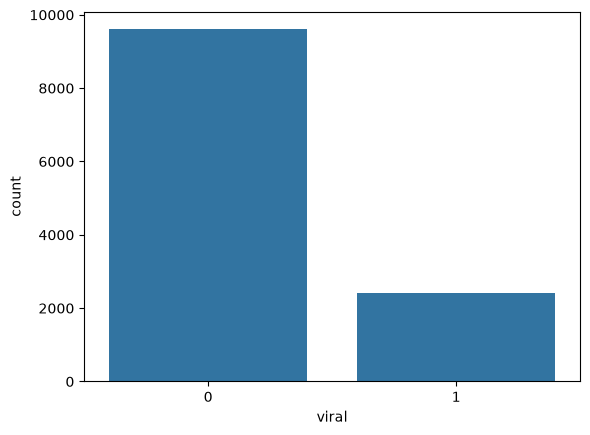

In [398]:
sns.countplot(x="viral", data=df)

In [399]:
df["viral"].value_counts(normalize=True) * 100

viral
0    80.0
1    20.0
Name: proportion, dtype: float64

Target variable is moderately asymmetric, which may affect the choice of evaluation metrics.

Since the target variable is directly derived from the 'views' feature (20% most viewed videos are classified as viral), we will have to drop it from the dataset to prevent leakage.

In [400]:
df.drop(['views'], axis=1, inplace=True)

## Train/Test Split

Split the dataset into train and test sets. Use stratified sampling to ensure that the distribution of the target variable is similar in all sets. The validation set will be generated during cross-validation.

In [401]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["viral"])
len(df_train), len(df_test)

(9600, 2400)

In [402]:
df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

y_train = df_train["viral"]
y_test = df_test["viral"]

## EDA

(We are leaving the target in the numerical feature list because we will be looking at the correlations between the target and these features)

In [403]:
numerical = ["duration_sec", "title_length", "tags_count", "description_length", "subscriber_count", "likes", "comments", "shares", "viral"]

categorical = ["category", "thumbnail_face", "upload_hour", "upload_day"]

### NUMERICAL FEATURE ANALYSIS

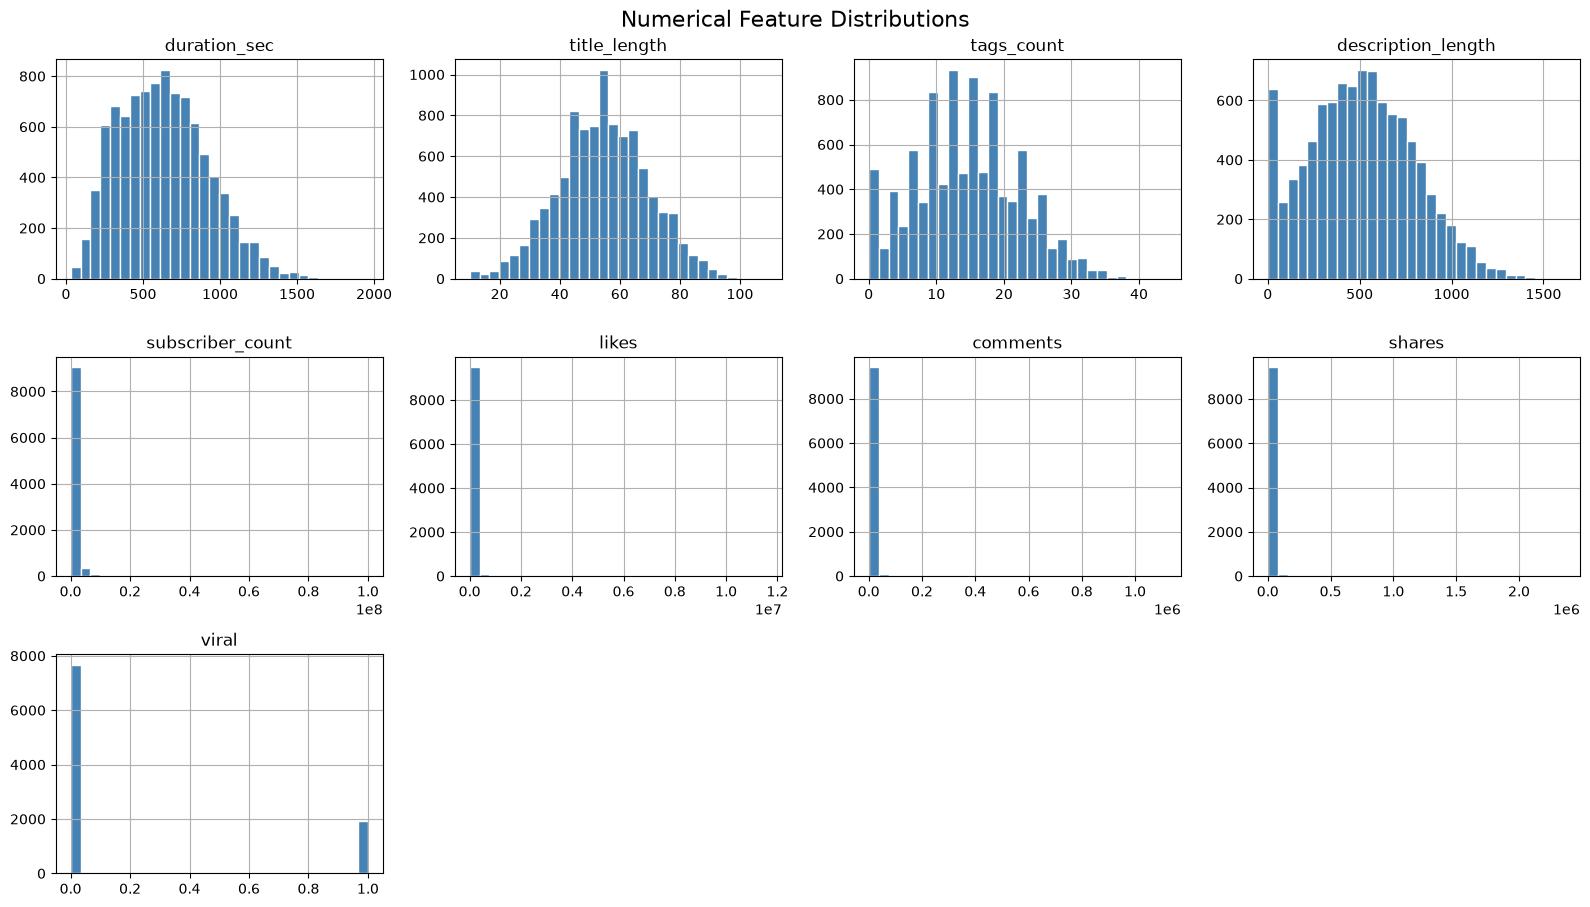

In [404]:
df_train[numerical].hist(bins=30, figsize=(16, 12), 
                        layout=(4, 4), color='steelblue', 
                        edgecolor='white')
plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

We can see that most of the numerical features are right skewed, which is common in social media data. We will apply log transformation to these features to make them more normally distributed (consider box plot for outlier detection). This is essential for the logistic regression model, as it requires the features to be normally distributed for better performance, but isn't strictly necessary for tree-based models.

In [405]:
df_train_log = df_train.copy()

for col in ["subscriber_count", "likes", "comments", "shares"]:
    df_train_log[f"{col}_log"] = np.log1p(df_train_log[col])

Created a separate DataFrame with log-transformed features.

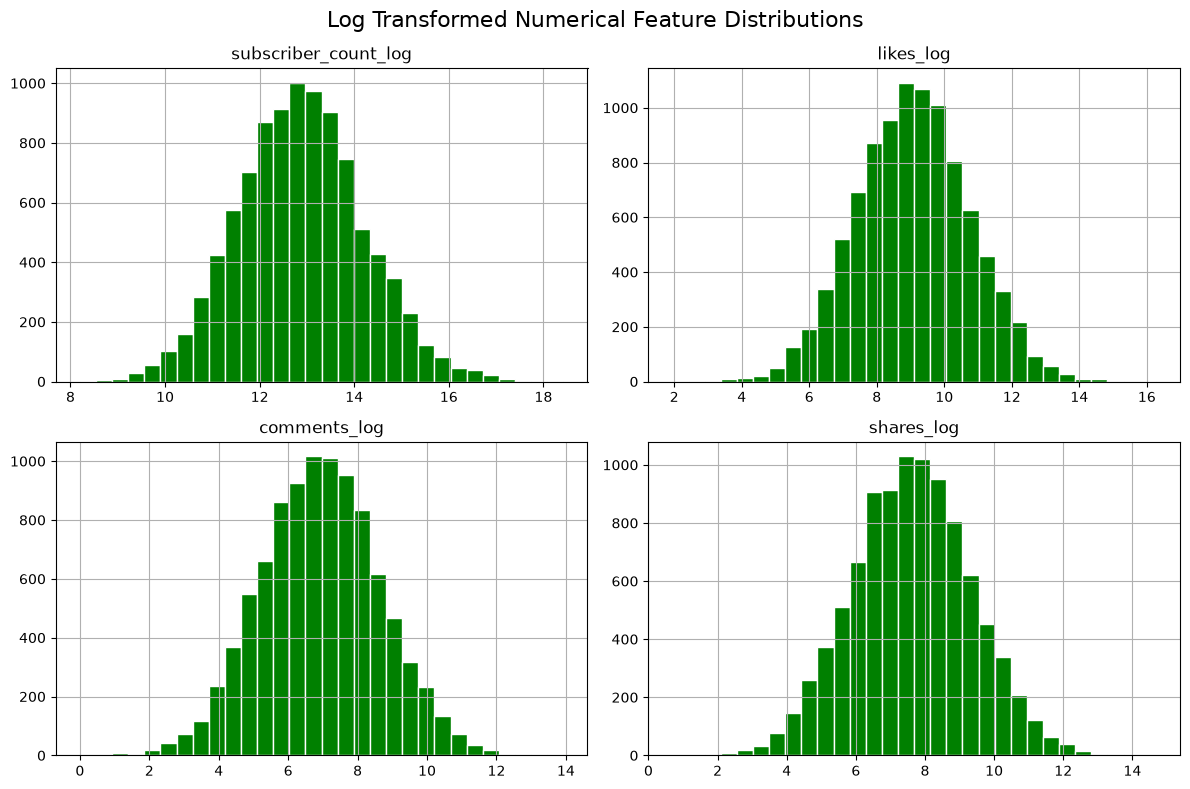

In [406]:
df_train_log[["subscriber_count_log", "likes_log", "comments_log", "shares_log"]].hist(bins=30,
                        figsize=(12, 8), color='green', 
                        edgecolor='white')
plt.suptitle('Log Transformed Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

### CATEGORICAL FEATURE ANALYSIS

category: 15 unique values


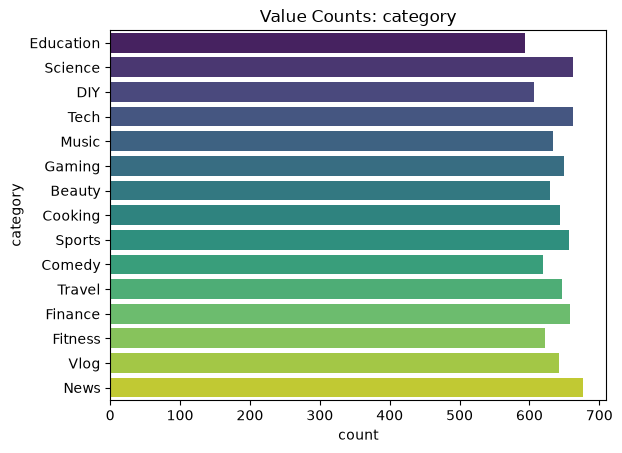

thumbnail_face: 2 unique values


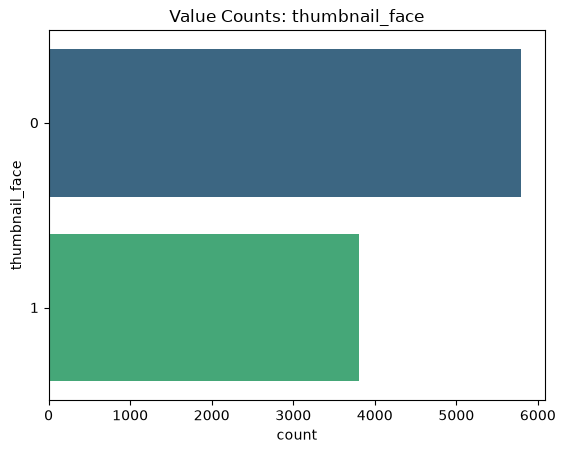

upload_hour: 24 unique values


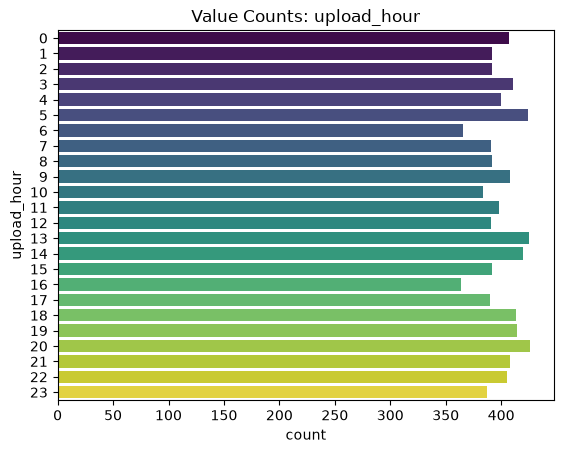

upload_day: 7 unique values


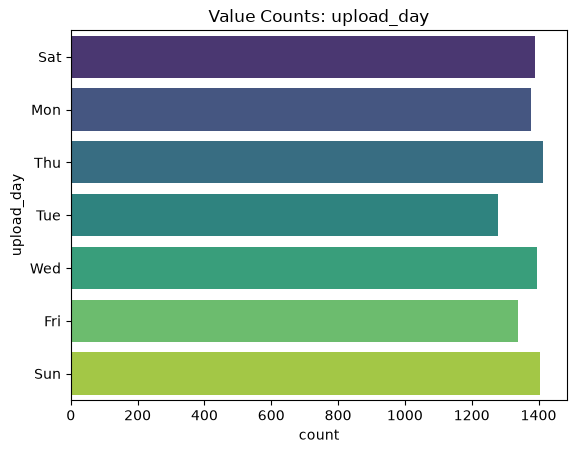

In [407]:
for cat in categorical:
    n_unique = df_train[cat].nunique()
    print(f"{cat}: {n_unique} unique values")
    
    if n_unique <= 24:
        sns.countplot(y=cat, data=df_train, palette='viridis', hue=cat, legend=None)
        plt.title(f'Value Counts: {cat}')
        plt.show()

### FEATURE IMPORTANCE ANALYSIS

#### RISK RATIO

In [408]:
from IPython.display import display

global_viral = df_train.viral.mean()

for cat in categorical:
    print(cat)
    df_group = df_train.groupby(cat).viral.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_viral
    df_group['risk'] = df_group['mean'] / global_viral
    display(df_group)

category


,mean,count,diff,risk
category,,,,
Beauty,0.219396,629,0.019396,1.096979
Comedy,0.365105,619,0.165105,1.825525
Cooking,0.170807,644,-0.029193,0.854037
DIY,0.128713,606,-0.071287,0.643564
Education,0.116358,593,-0.083642,0.581788
Finance,0.139818,658,-0.060182,0.699088
Fitness,0.118971,622,-0.081029,0.594855
Gaming,0.257319,649,0.057319,1.286595
Music,0.582019,634,0.382019,2.910095


thumbnail_face


,mean,count,diff,risk
thumbnail_face,,,,
0,0.182289,5793,-0.017711,0.911445
1,0.226950,3807,0.026950,1.134752


upload_hour


,mean,count,diff,risk
upload_hour,,,,
0,0.211302,407,0.011302,1.056511
1,0.163265,392,-0.036735,0.816327
2,0.158163,392,-0.041837,0.790816
3,0.170316,411,-0.029684,0.851582
4,0.210000,400,0.010000,1.050000
5,0.205189,424,0.005189,1.025943
6,0.193989,366,-0.006011,0.969945
7,0.225064,391,0.025064,1.125320
8,0.206633,392,0.006633,1.033163


upload_day


,mean,count,diff,risk
upload_day,,,,
Fri,0.203883,1339,0.003883,1.019417
Mon,0.211901,1378,0.011901,1.059507
Sat,0.186916,1391,-0.013084,0.934579
Sun,0.192883,1405,-0.007117,0.964413
Thu,0.205799,1414,0.005799,1.028996
Tue,0.196247,1279,-0.003753,0.981235
Wed,0.202296,1394,0.002296,1.011478


It seems that certain classes within the different categorical features increase the probability of the target being positive i.e. the "music" class is almost three times as likely to make a video viral. Apparently,
upload_day and upload_hour by themselves don't influence much the probability of virality, however after some research, we suspect that combining these features (through feature engineering) might yield a better predictor variable.

#### MUTUAL INFORMATION

In [409]:
from sklearn.metrics import mutual_info_score

def mutual_info_viral_score(series):
    return mutual_info_score(series, df_train.viral)

info_gain = df_train[categorical].apply(mutual_info_viral_score)
info_gain.sort_values(ascending=False)

category          0.045265
thumbnail_face    0.001477
upload_hour       0.001173
upload_day        0.000195
dtype: float64

The mutual information score confirms what was suggested by risk ratio analysis: the "category" feature seems to wield more predictive value than the rest of the categorical features.

#### CORRELATION ANALYSIS

In [410]:
df_train[numerical].corr()

,duration_sec,title_length,tags_count,description_length,subscriber_count,likes,comments,shares,viral
duration_sec,1.000000,0.003593,-0.002113,-0.000373,-0.171559,-0.090953,-0.092639,-0.094384,-0.164612
title_length,0.003593,1.000000,-0.007105,-0.002825,0.002511,0.010425,0.008206,0.009590,-0.002305
tags_count,-0.002113,-0.007105,1.000000,0.004313,0.010814,0.017301,0.017144,0.017537,0.026662
description_length,-0.000373,-0.002825,0.004313,1.000000,-0.007474,-0.001355,0.002585,0.001355,-0.014431
subscriber_count,-0.171559,0.002511,0.010814,-0.007474,1.000000,0.663346,0.612804,0.640756,0.402984
likes,-0.090953,0.010425,0.017301,-0.001355,0.663346,1.000000,0.961569,0.963020,0.293353
comments,-0.092639,0.008206,0.017144,0.002585,0.612804,0.961569,1.000000,0.937596,0.293365
shares,-0.094384,0.009590,0.017537,0.001355,0.640756,0.963020,0.937596,1.000000,0.292287
viral,-0.164612,-0.002305,0.026662,-0.014431,0.402984,0.293353,0.293365,0.292287,1.000000


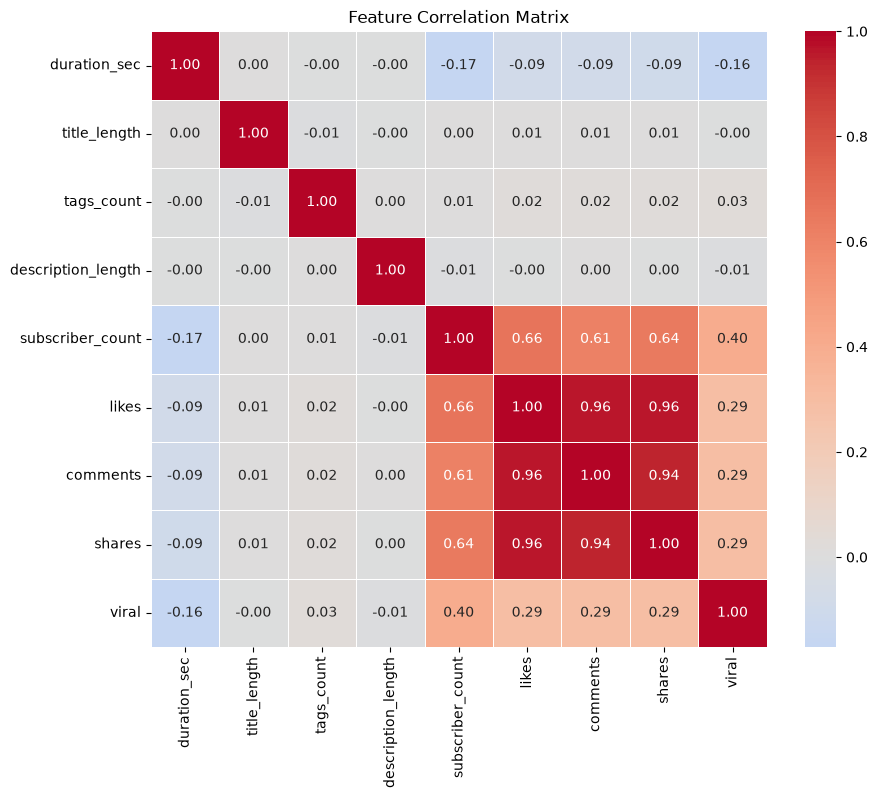

In [411]:
plt.figure(figsize=(10, 8))
corr_matrix = df_train[numerical].corr()

sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

Pearson correlation measures linear relationships, hence it is affected by outliers that skew data.  We used the log transformed numerical features and repeated the analysis.

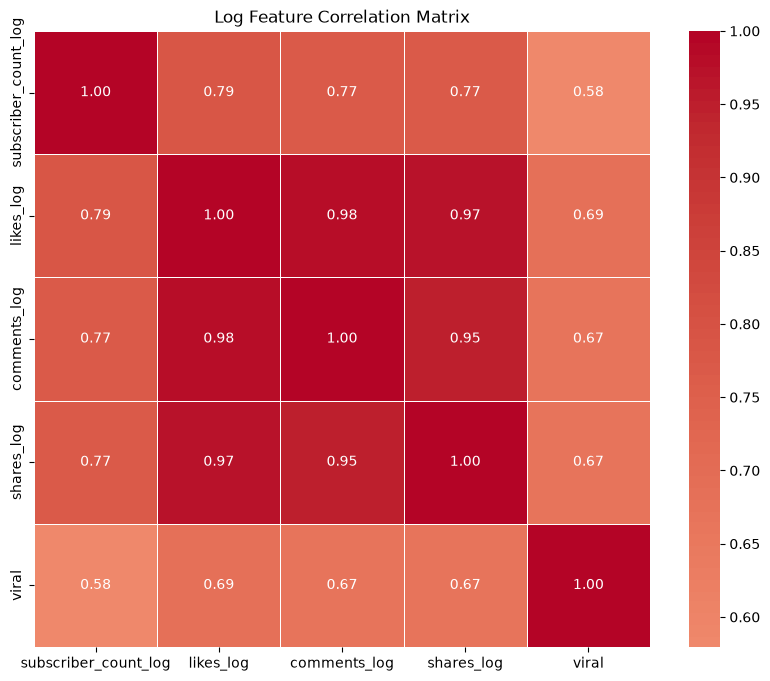

In [412]:
plt.figure(figsize=(10, 8))
corr_matrix = df_train_log[["subscriber_count_log", "likes_log", "comments_log", "shares_log", "viral"]].corr()

sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)
plt.title('Log Feature Correlation Matrix')
plt.show()

Correlations increased significantly between the log transformed features and the target. Also, there seems to be multi-collinearity between 'shares', 'comments' and 'likes', which given our domain knowledge is expected, as these metrics are often interrelated in social media content. Due to the fact that these features aren't useful for predicting virality beforehand (and would introduce leakage to the model), it makes sense to drop them from the dataset.

(think about feature engineering upload_day/upload_hour into bins for tree-based, and sin/cos for linear model)

## MODEL TRAINING

Dropping the target variable as well as shares, comments and likes features as discussed in the EDA analysis.

In [413]:
df_train.drop(['viral', 'shares', 'comments', 'likes'], axis=1, inplace=True)
df_test.drop(['viral', 'shares', 'comments', 'likes'], axis=1, inplace=True)

numerical_features = ['duration_sec', 'title_length', 'tags_count', 'description_length', 'log_subscriber_count']

### Linear-model Preprocessing and Feature Engineering

In [414]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

df_train_linear = df_train.copy()
df_test_linear = df_test.copy()

# Log transform the subscriber count feature
def log_transform_subscriber_count(df):
    df['log_subscriber_count'] = np.log1p(df['subscriber_count'])
    df.drop(columns=['subscriber_count'], inplace=True)

    return df

# Use sine and cosine transformations for the upload hour feature (hours are cyclical)
def add_cyclical_features(df):
    df['hour_sin'] = np.sin(2 * np.pi * df['upload_hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['upload_hour'] / 24)
    df = df.drop(columns=['upload_hour'])

    return df

### Logistic Regression

In [415]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

Manually looping through hyperparameters and cross-validation folds, instead of using GridSearchCV/RandomizedSearchCV. Due to stateful transformations such as StandardScaler or DictVectorizer we've fitted and transformed each fold separately.

In [416]:
# Hyperparameter tuning for Logistic Regression using Stratified K-Fold cross-validation
c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Outer Loop: Iterate over each hyperparameter candidate (C)
for C in c_values:
    fold_roc_aucs = []
    fold_pr_aucs = []
    fold_train_roc_aucs = []
    fold_train_pr_aucs = []
    # Inner Loop: Iterate over the 5 training/validation splits
    for train_idx, val_idx in cv.split(df_train_linear, y_train):
        # 1. Slice the fold data
        X_fold_train, y_fold_train = df_train_linear.iloc[train_idx], y_train.iloc[train_idx]
        X_fold_val, y_fold_val     = df_train_linear.iloc[val_idx], y_train.iloc[val_idx]

        # 2. Log transform the subscriber count feature for both fold train and fold validation
        log_transform_subscriber_count(X_fold_train)
        log_transform_subscriber_count(X_fold_val)

        # 3. Scale data (Fit ONLY on fold_train, transform both)
        scaler = StandardScaler()
        X_fold_train[numerical_features] = scaler.fit_transform(X_fold_train[numerical_features])
        X_fold_val[numerical_features] = scaler.transform(X_fold_val[numerical_features])

        # 4. Create cyclical features for both fold train and fold validation and drop original
        X_fold_train = add_cyclical_features(X_fold_train)
        X_fold_val = add_cyclical_features(X_fold_val)

        # 5. One-hot encode categorical features
        train_dicts_linear = X_fold_train.to_dict(orient='records')
        dv = DictVectorizer(sparse=False)

        X_fold_train = dv.fit_transform(train_dicts_linear)
        X_fold_val = dv.transform(X_fold_val.to_dict(orient='records'))
        
        # 6. Train Logistic Regression with current C
        model = LogisticRegression(C=C, max_iter=1000, random_state=42)
        model.fit(X_fold_train, y_fold_train)
        
        # 7. Predict probabilities on validation fold & calculate metrics
        val_probs = model.predict_proba(X_fold_val)[:, 1]
        train_probs = model.predict_proba(X_fold_train)[:, 1]
        
        fold_roc_aucs.append(roc_auc_score(y_fold_val, val_probs))
        fold_pr_aucs.append(average_precision_score(y_fold_val, val_probs))
        fold_train_roc_aucs.append(roc_auc_score(y_fold_train, train_probs))
        fold_train_pr_aucs.append(average_precision_score(y_fold_train, train_probs))
        
    # 8. Average the scores across the 5 folds for this C value
    print(
        f"C = {C:<6} | "
        f"Mean ROC AUC: {np.mean(fold_roc_aucs):.4f} (+/- {np.std(fold_roc_aucs):.4f}) | "
        f"Mean PR AUC: {np.mean(fold_pr_aucs):.4f} (+/- {np.std(fold_pr_aucs):.4f}) | "
        f"Mean Train ROC AUC: {np.mean(fold_train_roc_aucs):.4f} (+/- {np.std(fold_train_roc_aucs):.4f}) | "
        f"Mean Train PR AUC: {np.mean(fold_train_pr_aucs):.4f} (+/- {np.std(fold_train_pr_aucs):.4f})")

C = 0.001  | Mean ROC AUC: 0.9025 (+/- 0.0114) | Mean PR AUC: 0.7306 (+/- 0.0222) | Mean Train ROC AUC: 0.9035 (+/- 0.0024) | Mean Train PR AUC: 0.7322 (+/- 0.0047)
C = 0.01   | Mean ROC AUC: 0.9065 (+/- 0.0103) | Mean PR AUC: 0.7392 (+/- 0.0220) | Mean Train ROC AUC: 0.9080 (+/- 0.0025) | Mean Train PR AUC: 0.7419 (+/- 0.0052)
C = 0.1    | Mean ROC AUC: 0.9062 (+/- 0.0100) | Mean PR AUC: 0.7385 (+/- 0.0217) | Mean Train ROC AUC: 0.9085 (+/- 0.0025) | Mean Train PR AUC: 0.7430 (+/- 0.0052)
C = 1.0    | Mean ROC AUC: 0.9059 (+/- 0.0099) | Mean PR AUC: 0.7379 (+/- 0.0216) | Mean Train ROC AUC: 0.9086 (+/- 0.0025) | Mean Train PR AUC: 0.7430 (+/- 0.0052)
C = 10.0   | Mean ROC AUC: 0.9059 (+/- 0.0099) | Mean PR AUC: 0.7379 (+/- 0.0216) | Mean Train ROC AUC: 0.9086 (+/- 0.0025) | Mean Train PR AUC: 0.7430 (+/- 0.0052)
C = 100.0  | Mean ROC AUC: 0.9059 (+/- 0.0099) | Mean PR AUC: 0.7379 (+/- 0.0216) | Mean Train ROC AUC: 0.9086 (+/- 0.0025) | Mean Train PR AUC: 0.7430 (+/- 0.0052)


All C values give a solid performance with minimal overfitting. Will be selecting the one with the highest mean validation PR-AUC (C=0.01).

The ROC-AUC score measures the model's ability to distinguish between positive and negative classes, while the PR-AUC score focuses is much more sensitive to false positives on the minority class, which is particularly useful for imbalanced datasets. These metrics together give a more complete picture of the model's predictive capabilities and help in assessing its effectiveness in real-world scenarios. We will be using PR-AUC as our primary evaluation metric.

### Tree-based Model Preprocessing and Feature Engineering

In order to reduce the cardinality of 'upload_hour' and 'upload_day' when using DictVectorizer, we can group them into broader categories such as morning, afternoon, evening, and night for 'upload_hour', and weekday vs weekend for 'upload_day'. We then further combine them into a single feature representing the time period of the upload, which can help capture temporal patterns more effectively.

In [ ]:
# Create a copy of the original dataframes
df_train_tree = df_train.copy()
df_test_tree = df_test.copy()

# Bin the hours into 4 logical parts of the day
# 0-5: Night, 6-11: Morning, 12-17: Afternoon, 18-23: Evening
def bin_hours(df):
    hour_bins = [-1, 5, 11, 17, 23]
    hour_labels = ['Night', 'Morning', 'Afternoon', 'Evening']
    df['time_of_day'] = pd.cut(df['upload_hour'], bins=hour_bins, labels=hour_labels)
    return df

# Bin the days (e.g., Weekday vs Weekend)
def bin_days(df):
    weekend = ['sat', 'sun']
    df['day_type'] = np.where(df['upload_day'].isin(weekend), 'Weekend', 'Weekday')
    return df

# Combine them into a single interaction feature (8 total bins)
def create_day_time_bin(df):
    df['day_time_bin'] = df['day_type'].astype(str) + '_' + df['time_of_day'].astype(str)
    return df

# Apply the binning functions to datasets outside of any cross-validation loop since they are stateless transformations
df_train_tree = bin_hours(df_train_tree)
df_test_tree = bin_hours(df_test_tree)

df_train_tree = bin_days(df_train_tree)
df_test_tree = bin_days(df_test_tree)

df_train_tree = create_day_time_bin(df_train_tree)
df_test_tree = create_day_time_bin(df_test_tree)

# Dropping the original upload hour and day columns along with intermediate features
df_train_tree.drop(['upload_hour', 'upload_day', 'time_of_day', 'day_type'], axis=1, inplace=True)
df_test_tree.drop(['upload_hour', 'upload_day', 'time_of_day', 'day_type'], axis=1, inplace=True)

df_train_tree.head()

,category,duration_sec,title_length,thumbnail_face,tags_count,description_length,subscriber_count,day_time_bin
0,Education,1201,72,0,15,569,2789543,Weekday_Afternoon
1,Science,913,55,0,12,368,410585,Weekday_Night
2,DIY,1154,58,0,20,528,1320364,Weekday_Morning
3,Tech,745,65,0,7,695,378847,Weekday_Night
4,Music,92,58,1,25,201,2656560,Weekday_Evening


### Decision Tree

In [186]:
from sklearn.tree import DecisionTreeClassifier

We will search the hyperparameter space for the decision tree to find the optimal combination of max_depth and min_samples_leaf that maximizes the validation PR-AUC score.

In [187]:
# Grid search for Decision Tree hyperparameters using manual loops
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores =[]

for max_depth in [2, 4, 6, 8, 10]:

    for min_samples_leaf in [1, 5, 10, 20, 100]:
        
        fold_roc_aucs = []
        fold_pr_aucs = []
        fold_train_roc_aucs = []
        fold_train_pr_aucs = []

        for train_idx, val_idx in cv.split(df_train_tree, y_train):
                # 1. Slice the fold data
                X_fold_train, y_fold_train = df_train_tree.iloc[train_idx], y_train.iloc[train_idx]
                X_fold_val, y_fold_val     = df_train_tree.iloc[val_idx], y_train.iloc[val_idx]

                # 2. One-hot encode the categorical features using DictVectorizer
                train_dicts = X_fold_train.to_dict(orient='records')
                test_dicts = X_fold_val.to_dict(orient='records')

                dv = DictVectorizer(sparse=False)

                X_fold_train = dv.fit_transform(train_dicts)
                X_fold_val = dv.transform(test_dicts)
                
                # 3. Train Decision Tree with current hyperparameters
                dt_model = DecisionTreeClassifier(random_state=42, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
                dt_model.fit(X_fold_train, y_fold_train)

                # 4. Predict probabilities on validation fold & calculate metrics
                val_probs = dt_model.predict_proba(X_fold_val)[:, 1]
                train_probs = dt_model.predict_proba(X_fold_train)[:, 1]
                        
                fold_roc_aucs.append(roc_auc_score(y_fold_val, val_probs))
                fold_pr_aucs.append(average_precision_score(y_fold_val, val_probs))
                fold_train_roc_aucs.append(roc_auc_score(y_fold_train, train_probs))
                fold_train_pr_aucs.append(average_precision_score(y_fold_train, train_probs))

        scores.append((max_depth, min_samples_leaf, np.mean(fold_pr_aucs), np.mean(fold_train_pr_aucs)))

        # 5. Average the scores across the 5 folds for max_depth and min_samples_leaf combination                
        print(
            f"max_depth = {max_depth:<6} | min_samples_leaf = {min_samples_leaf:<6} | "
            f"Mean ROC AUC: {np.mean(fold_roc_aucs):.4f} (+/- {np.std(fold_roc_aucs):.4f}) | "
            f"Mean PR AUC: {np.mean(fold_pr_aucs):.4f} (+/- {np.std(fold_pr_aucs):.4f}) | "
            f"Mean Train ROC AUC: {np.mean(fold_train_roc_aucs):.4f} (+/- {np.std(fold_train_roc_aucs):.4f}) | "
            f"Mean Train PR AUC: {np.mean(fold_train_pr_aucs):.4f} (+/- {np.std(fold_train_pr_aucs):.4f})")        
                

max_depth = 2      | min_samples_leaf = 1      | Mean ROC AUC: 0.8713 (+/- 0.0108) | Mean PR AUC: 0.6279 (+/- 0.0234) | Mean Train ROC AUC: 0.8757 (+/- 0.0033) | Mean Train PR AUC: 0.6387 (+/- 0.0048)
max_depth = 2      | min_samples_leaf = 5      | Mean ROC AUC: 0.8713 (+/- 0.0108) | Mean PR AUC: 0.6279 (+/- 0.0234) | Mean Train ROC AUC: 0.8757 (+/- 0.0033) | Mean Train PR AUC: 0.6387 (+/- 0.0048)
max_depth = 2      | min_samples_leaf = 10     | Mean ROC AUC: 0.8713 (+/- 0.0108) | Mean PR AUC: 0.6279 (+/- 0.0234) | Mean Train ROC AUC: 0.8757 (+/- 0.0033) | Mean Train PR AUC: 0.6387 (+/- 0.0048)
max_depth = 2      | min_samples_leaf = 20     | Mean ROC AUC: 0.8713 (+/- 0.0108) | Mean PR AUC: 0.6279 (+/- 0.0234) | Mean Train ROC AUC: 0.8757 (+/- 0.0033) | Mean Train PR AUC: 0.6387 (+/- 0.0048)
max_depth = 2      | min_samples_leaf = 100    | Mean ROC AUC: 0.8713 (+/- 0.0108) | Mean PR AUC: 0.6279 (+/- 0.0234) | Mean Train ROC AUC: 0.8757 (+/- 0.0033) | Mean Train PR AUC: 0.6387 (+/- 0.0

Plotting the PR AUC scores in a heatmap.

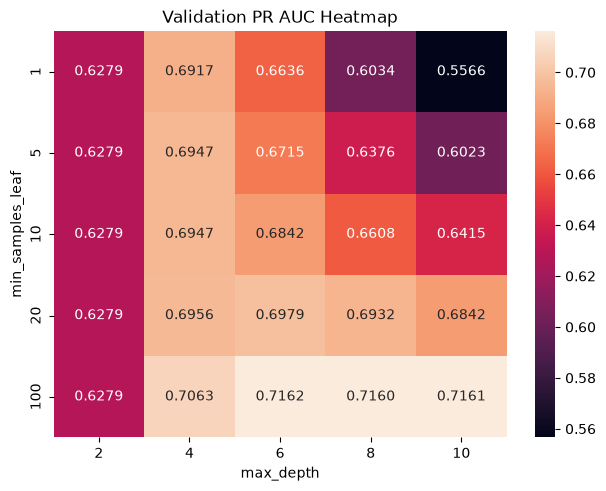

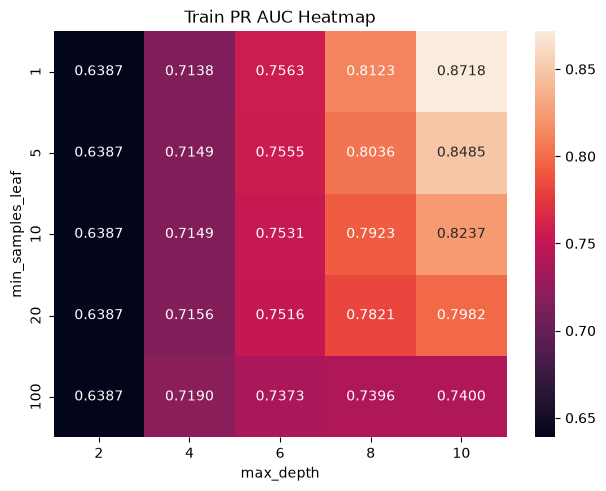

In [188]:
columns = ['max_depth', 'min_samples_leaf', 'pr_auc', 'train_pr_auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='pr_auc')
df_scores_pivot.round(3)

df_scores_pivot_train = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='train_pr_auc')
df_scores_pivot_train.round(3)

sns.heatmap(df_scores_pivot, annot=True, fmt=".4f")
plt.tight_layout()
plt.xlabel('max_depth')
plt.ylabel('min_samples_leaf')
plt.title('Validation PR AUC Heatmap')

plt.show()

sns.heatmap(df_scores_pivot_train, annot=True, fmt=".4f")
plt.tight_layout()
plt.xlabel('max_depth')
plt.ylabel('min_samples_leaf')
plt.title('Train PR AUC Heatmap')

plt.show()


The optimal hyperparameter combination for the decision tree is max_depth=6 and min_samples_leaf=100.

In [209]:
from sklearn.tree import export_text

train_dicts = df_train_tree.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
                
dt_model = DecisionTreeClassifier(random_state=42, max_depth=6, min_samples_leaf=100)
dt_model.fit(X_train, y_train)

print(export_text(dt_model, feature_names=list(dv.get_feature_names_out())))

|--- subscriber_count <= 1177256.00
|   |--- subscriber_count <= 608101.00
|   |   |--- subscriber_count <= 364332.00
|   |   |   |--- subscriber_count <= 214562.50
|   |   |   |   |--- subscriber_count <= 171935.50
|   |   |   |   |   |--- subscriber_count <= 134551.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- subscriber_count >  134551.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- subscriber_count >  171935.50
|   |   |   |   |   |--- tags_count <= 18.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- tags_count >  18.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- subscriber_count >  214562.50
|   |   |   |   |--- category=Beauty <= 0.50
|   |   |   |   |   |--- title_length <= 33.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- title_length >  33.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- category=Beauty >  0.50
|   |   |   |   |   |--- class: 0
|   |   |--- subscriber_count >  364332.

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

We will perform a grid search to tune max_depth and n_estimators to find the optimal combination that maximizes the validation PR-AUC score.

In [191]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for max_depth in [1, 5, 10, 20]:

    for n in range(10, 201, 20):

        fold_roc_aucs = []
        fold_pr_aucs = []
        fold_train_roc_aucs = []
        fold_train_pr_aucs = []

        for train_idx, valid_idx in cv.split(df_train_tree, y_train):
                
            # 1. Split the data into training and validation sets for this fold
            X_fold_train, y_fold_train = df_train_tree.iloc[train_idx], y_train.iloc[train_idx]
            X_fold_val, y_fold_val     = df_train_tree.iloc[valid_idx], y_train.iloc[valid_idx]
                
            # 2. One-hot encode the categorical features using DictVectorizer
            train_dicts = X_fold_train.to_dict(orient='records')
            test_dicts = X_fold_val.to_dict(orient='records')
                
            dv = DictVectorizer(sparse=False)
                
            X_fold_train = dv.fit_transform(train_dicts)
            X_fold_val = dv.transform(test_dicts)
            
            # 3. Initialize the Random Forest model with current hyperparameters
            rf_model = RandomForestClassifier(
                n_estimators=n,
                max_depth=max_depth,
                random_state=42
            )
            # 4. Fit the model on the training fold
            rf_model.fit(X_fold_train, y_fold_train)

            # 5. Predict probabilities on validation fold & calculate metrics
            val_probs = rf_model.predict_proba(X_fold_val)[:, 1]
            train_probs = rf_model.predict_proba(X_fold_train)[:, 1]

        
            fold_roc_aucs.append(roc_auc_score(y_fold_val, val_probs))
            fold_pr_aucs.append(average_precision_score(y_fold_val, val_probs))
            fold_train_roc_aucs.append(roc_auc_score(y_fold_train, train_probs))
            fold_train_pr_aucs.append(average_precision_score(y_fold_train, train_probs))

        scores.append((max_depth, n, np.mean(fold_pr_aucs), np.mean(fold_train_pr_aucs)))
        
        print(
            f"max_depth = {max_depth:<6} | n_estimators = {n:<6} | "
            f"Mean ROC AUC: {np.mean(fold_roc_aucs):.4f} (+/- {np.std(fold_roc_aucs):.4f}) | "
            f"Mean PR AUC: {np.mean(fold_pr_aucs):.4f} (+/- {np.std(fold_pr_aucs):.4f}) | "
            f"Mean Train ROC AUC: {np.mean(fold_train_roc_aucs):.4f} (+/- {np.std(fold_train_roc_aucs):.4f}) | "
            f"Mean Train PR AUC: {np.mean(fold_train_pr_aucs):.4f} (+/- {np.std(fold_train_pr_aucs):.4f})"
        )

        

max_depth = 1      | n_estimators = 10     | Mean ROC AUC: 0.8210 (+/- 0.0084) | Mean PR AUC: 0.5777 (+/- 0.0120) | Mean Train ROC AUC: 0.8237 (+/- 0.0085) | Mean Train PR AUC: 0.5822 (+/- 0.0103)
max_depth = 1      | n_estimators = 30     | Mean ROC AUC: 0.8299 (+/- 0.0111) | Mean PR AUC: 0.6100 (+/- 0.0076) | Mean Train ROC AUC: 0.8342 (+/- 0.0033) | Mean Train PR AUC: 0.6150 (+/- 0.0115)
max_depth = 1      | n_estimators = 50     | Mean ROC AUC: 0.8290 (+/- 0.0066) | Mean PR AUC: 0.5975 (+/- 0.0107) | Mean Train ROC AUC: 0.8329 (+/- 0.0039) | Mean Train PR AUC: 0.6024 (+/- 0.0064)
max_depth = 1      | n_estimators = 70     | Mean ROC AUC: 0.8271 (+/- 0.0070) | Mean PR AUC: 0.5913 (+/- 0.0121) | Mean Train ROC AUC: 0.8314 (+/- 0.0028) | Mean Train PR AUC: 0.5966 (+/- 0.0054)
max_depth = 1      | n_estimators = 90     | Mean ROC AUC: 0.8249 (+/- 0.0087) | Mean PR AUC: 0.5881 (+/- 0.0127) | Mean Train ROC AUC: 0.8295 (+/- 0.0021) | Mean Train PR AUC: 0.5944 (+/- 0.0070)
max_depth = 1  

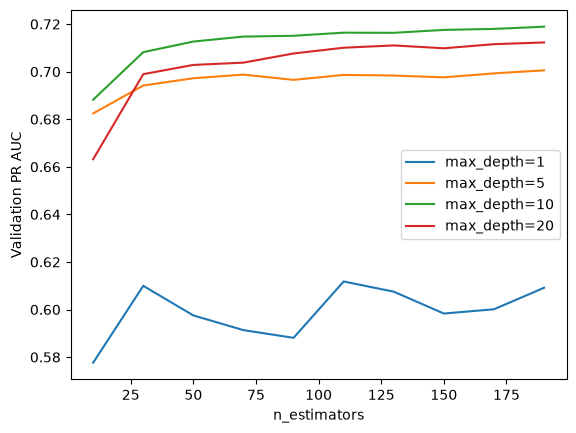

In [192]:
columns = ['max_depth', 'n_estimators', 'val_pr', 'train_pr']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [1, 5, 10, 20]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.val_pr,
             label='max_depth=%d' % d)

    plt.xlabel('n_estimators')
    plt.ylabel('Validation PR AUC')

plt.legend()
plt.show()

The best max_depth for the random forest seems to be 10.

Now that we've fixed max_depth=10, we will perform a grid search to tune min_samples_leaf to find the optimal value that maximizes the validation PR-AUC score.

In [193]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for min_samples_leaf in [5, 10, 20, 50, 100]:

    for n in range(10, 201, 20):

        fold_roc_aucs = []
        fold_pr_aucs = []
        fold_train_roc_aucs = []
        fold_train_pr_aucs = []

        for train_idx, valid_idx in cv.split(df_train_tree, y_train):
                
            # 1. Split the data into training and validation sets for this fold
            X_fold_train, y_fold_train = df_train_tree.iloc[train_idx], y_train.iloc[train_idx]
            X_fold_val, y_fold_val     = df_train_tree.iloc[valid_idx], y_train.iloc[valid_idx]
                
            # 2. One-hot encode the categorical features using DictVectorizer
            train_dicts = X_fold_train.to_dict(orient='records')
            test_dicts = X_fold_val.to_dict(orient='records')
                
            dv = DictVectorizer(sparse=False)
                
            X_fold_train = dv.fit_transform(train_dicts)
            X_fold_val = dv.transform(test_dicts)

            # 3. Initialize the Random Forest model with current hyperparameters
            rf_model = RandomForestClassifier(
                        n_estimators=n,
                        max_depth=10,
                        min_samples_leaf=min_samples_leaf,
                        random_state=42
                        )

            # 4. Fit the model on the training fold
            rf_model.fit(X_fold_train, y_fold_train)

            # 5. Predict probabilities on validation fold & calculate metrics
            val_probs = rf_model.predict_proba(X_fold_val)[:, 1]
            train_probs = rf_model.predict_proba(X_fold_train)[:, 1]

        
            fold_roc_aucs.append(roc_auc_score(y_fold_val, val_probs))
            fold_pr_aucs.append(average_precision_score(y_fold_val, val_probs))
            fold_train_roc_aucs.append(roc_auc_score(y_fold_train, train_probs))
            fold_train_pr_aucs.append(average_precision_score(y_fold_train, train_probs))

        scores.append((min_samples_leaf, n, np.mean(fold_pr_aucs), np.mean(fold_train_pr_aucs)))
        
        print(
            f"min_samples_leaf = {min_samples_leaf:<6} | n_estimators = {n:<6} | "
            f"Mean ROC AUC: {np.mean(fold_roc_aucs):.4f} (+/- {np.std(fold_roc_aucs):.4f}) | "
            f"Mean PR AUC: {np.mean(fold_pr_aucs):.4f} (+/- {np.std(fold_pr_aucs):.4f}) | "
            f"Mean Train ROC AUC: {np.mean(fold_train_roc_aucs):.4f} (+/- {np.std(fold_train_roc_aucs):.4f}) | "
            f"Mean Train PR AUC: {np.mean(fold_train_pr_aucs):.4f} (+/- {np.std(fold_train_pr_aucs):.4f})"
        )

min_samples_leaf = 5      | n_estimators = 10     | Mean ROC AUC: 0.8853 (+/- 0.0145) | Mean PR AUC: 0.6988 (+/- 0.0261) | Mean Train ROC AUC: 0.9352 (+/- 0.0006) | Mean Train PR AUC: 0.8118 (+/- 0.0026)
min_samples_leaf = 5      | n_estimators = 30     | Mean ROC AUC: 0.8934 (+/- 0.0118) | Mean PR AUC: 0.7154 (+/- 0.0222) | Mean Train ROC AUC: 0.9388 (+/- 0.0015) | Mean Train PR AUC: 0.8233 (+/- 0.0039)
min_samples_leaf = 5      | n_estimators = 50     | Mean ROC AUC: 0.8951 (+/- 0.0118) | Mean PR AUC: 0.7174 (+/- 0.0187) | Mean Train ROC AUC: 0.9399 (+/- 0.0014) | Mean Train PR AUC: 0.8259 (+/- 0.0038)
min_samples_leaf = 5      | n_estimators = 70     | Mean ROC AUC: 0.8951 (+/- 0.0116) | Mean PR AUC: 0.7183 (+/- 0.0178) | Mean Train ROC AUC: 0.9404 (+/- 0.0012) | Mean Train PR AUC: 0.8265 (+/- 0.0035)
min_samples_leaf = 5      | n_estimators = 90     | Mean ROC AUC: 0.8958 (+/- 0.0115) | Mean PR AUC: 0.7182 (+/- 0.0171) | Mean Train ROC AUC: 0.9409 (+/- 0.0010) | Mean Train PR AUC: 

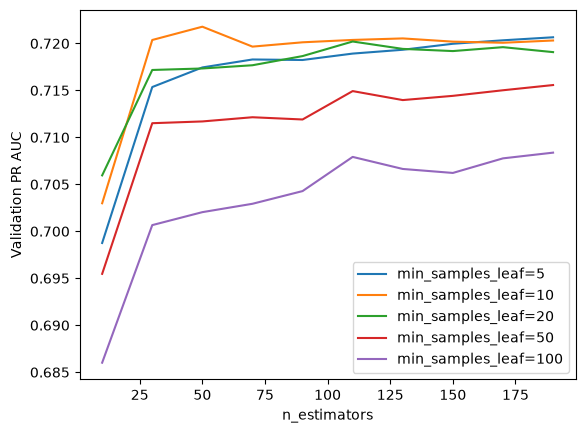

In [194]:
columns = ['min_samples_leaf', 'n_estimators', 'val_pr', 'train_pr']
df_scores = pd.DataFrame(scores, columns=columns)

values = [5, 10, 20, 50, 100]


for s in values:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.val_pr,
             label='min_samples_leaf=%d' % s)
    plt.xlabel('n_estimators')
    plt.ylabel('Validation PR AUC')

plt.legend()

The best min_samples_leaf for the random forest seems to be 10.

### XGBoost

In [195]:
import xgboost as xgb

In [196]:
# 1. Setup grid search and cross-validation
etas = [0.01, 0.05, 0.1, 0.3]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

records = []

# 2. Grid search + CV loop
for eta in etas:
    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "max_depth": 5,
        "eta": eta,
        "seed": 42,
    }

    for fold, (train_idx, val_idx) in enumerate(cv.split(df_train_tree, y_train)):
        train_dicts = df_train_tree.iloc[train_idx].to_dict(orient="records")
        val_dicts = df_train_tree.iloc[val_idx].to_dict(orient="records")

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        dtrain = xgb.DMatrix(X_train, label=y_train.iloc[train_idx])
        dval = xgb.DMatrix(X_val, label=y_train.iloc[val_idx])

        evals_result = {}
        xgb.train(
            params=params,
            dtrain=dtrain,
            num_boost_round=200,
            evals=[(dval, "val")],
            evals_result=evals_result,
            verbose_eval=False,
        )

        for r, score in enumerate(evals_result["val"]["aucpr"], start=1):
            records.append(
                {"eta": eta, "fold": fold, "boost_round": r, "prauc": score}
            )

# 3. Raw fold-level scores and mean CV scores per (eta, boost_round) for plotting
scores_df = pd.DataFrame(records)
cv_summary_df = scores_df.groupby(["eta", "boost_round"], as_index=False)["prauc"].mean()


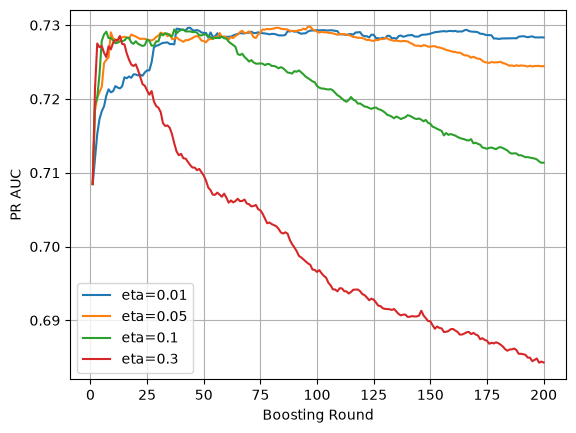

In [197]:
for eta, group in cv_summary_df.groupby("eta"):
    plt.plot(group["boost_round"], group["prauc"], label=f"eta={eta}")

plt.xlabel("Boosting Round")
plt.ylabel("PR AUC")
plt.legend()
plt.grid(True)
plt.show()

The optimal eta is 0.05.

In [198]:
cv_summary_df[cv_summary_df["prauc"] == cv_summary_df["prauc"].max() ]

,eta,boost_round,prauc
295,0.05,96,0.729789


In [199]:
# 1. Setup grid search and cross-validation
max_depths = [3, 5, 7, 9]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

records = []

# 2. Grid search + CV loop with fixed eta = 0.05
for md in max_depths:
    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "max_depth": md,
        "eta": 0.05,
        "seed": 42,
    }

    for fold, (train_idx, val_idx) in enumerate(cv.split(df_train_tree, y_train)):
        train_dicts = df_train_tree.iloc[train_idx].to_dict(orient="records")
        val_dicts = df_train_tree.iloc[val_idx].to_dict(orient="records")

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        dtrain = xgb.DMatrix(X_train, label=y_train.iloc[train_idx])
        dval = xgb.DMatrix(X_val, label=y_train.iloc[val_idx])

        evals_result = {}
        xgb.train(
            params=params,
            dtrain=dtrain,
            num_boost_round=200,
            evals=[(dval, "val")],
            evals_result=evals_result,
            verbose_eval=False,
        )

        for r, score in enumerate(evals_result["val"]["aucpr"], start=1):
            records.append(
                {"max_depth": md, "fold": fold, "boost_round": r, "prauc": score}
            )

# 3. Raw fold-level scores and mean CV scores per (max_depth, boost_round) for plotting
scores_df = pd.DataFrame(records)
cv_summary_df = scores_df.groupby(["max_depth", "boost_round"], as_index=False)["prauc"].mean()

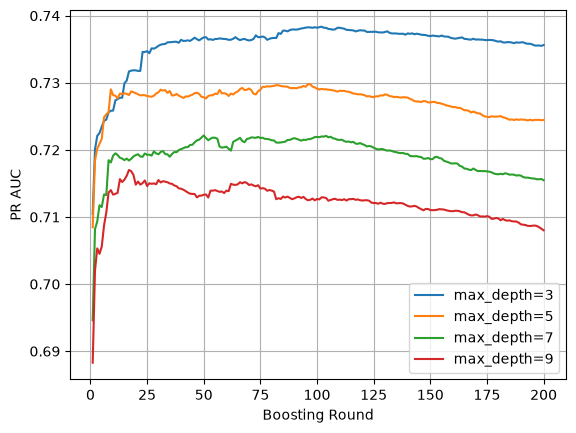

In [200]:
for md, group in cv_summary_df.groupby("max_depth"):
    plt.plot(group["boost_round"], group["prauc"], label=f"max_depth={md}")

plt.xlabel("Boosting Round")
plt.ylabel("PR AUC")
plt.legend()
plt.grid(True)
plt.show()

The optimal max_Depth is 3.

In [201]:
cv_summary_df[cv_summary_df["prauc"] == cv_summary_df["prauc"].max() ]

,max_depth,boost_round,prauc
101,3,102,0.738362


In [202]:
# 1. Setup grid search and cross-validation for min_child_weight
min_child_weights = [1, 10, 30]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

records = []

# 2. Grid search + CV loop with fixed eta =0.05 and max_depth=3
for mcw in min_child_weights:
    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "max_depth": 3,
        "eta": 0.05,
        "min_child_weight": mcw,
        "seed": 42,
    }

    for fold, (train_idx, val_idx) in enumerate(cv.split(df_train_tree, y_train)):
        train_dicts = df_train_tree.iloc[train_idx].to_dict(orient="records")
        val_dicts = df_train_tree.iloc[val_idx].to_dict(orient="records")

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        dtrain = xgb.DMatrix(X_train, label=y_train.iloc[train_idx])
        dval = xgb.DMatrix(X_val, label=y_train.iloc[val_idx])

        evals_result = {}
        xgb.train(
            params=params,
            dtrain=dtrain,
            num_boost_round=200,
            evals=[(dval, "val")],
            evals_result=evals_result,
            verbose_eval=False,
        )

        for r, score in enumerate(evals_result["val"]["aucpr"], start=1):
            records.append(
                {"min_child_weight": mcw, "fold": fold, "boost_round": r, "prauc": score}
            )

# 3. Raw fold-level scores and mean CV scores per (min_child_weight, boost_round) for plotting
scores_df = pd.DataFrame(records)
cv_summary_df = scores_df.groupby(["min_child_weight", "boost_round"], as_index=False)["prauc"].mean()

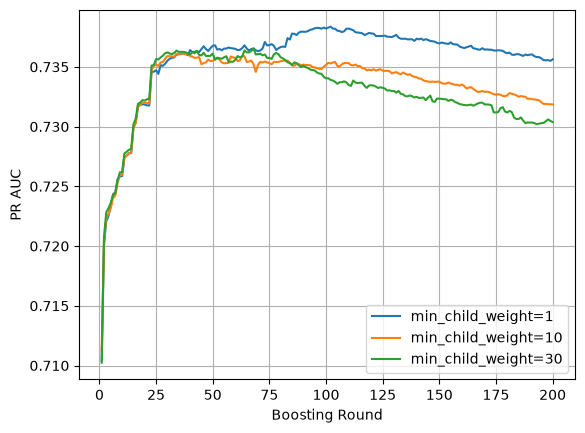

In [203]:
for mcw, group in cv_summary_df.groupby("min_child_weight"):
    plt.plot(group["boost_round"], group["prauc"], label=f"min_child_weight={mcw}")

plt.xlabel("Boosting Round")
plt.ylabel("PR AUC")
plt.legend()
plt.grid(True)
plt.show()

The optimal min_child_weight is 1.

In [204]:
cv_summary_df[cv_summary_df["prauc"] == cv_summary_df["prauc"].max() ]

,min_child_weight,boost_round,prauc
101,1,102,0.738362


## Final Model Selection

The best mean PR AUC scores for the models are ->
Logistic Regression: 0.7392,
Decision Tree: 0.7162,
Random Forest: 0.7218,
XGBoost: 0.7384

In [387]:
# Final training and evaluation of the logistic regression model on hold-out test set
C=0.01

# 1. Log transform the subscriber count feature
log_transform_subscriber_count(df_train_linear)
log_transform_subscriber_count(df_test_linear)

# 2. Scale data
scaler = StandardScaler()
df_train_linear[numerical_features] = scaler.fit_transform(df_train_linear[numerical_features])
df_test_linear[numerical_features] = scaler.transform(df_test_linear[numerical_features])

# 3. Create cyclical features
df_train_linear = add_cyclical_features(df_train_linear)
df_test_linear = add_cyclical_features(df_test_linear)

# 4. One-hot encode categorical features
train_dicts_linear = df_train_linear.to_dict(orient='records')
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts_linear)
X_test = dv.transform(df_test_linear.to_dict(orient='records'))

# 5. Train Logistic Regression with tuned hyperparameter
lr_final_model = LogisticRegression(C=C, max_iter=1000, random_state=42)
lr_final_model.fit(X_train, y_train)

# 6. Predict probabilities
test_probs = lr_final_model.predict_proba(X_test)[:, 1]
train_probs = lr_final_model.predict_proba(X_train)[:, 1]

print("Test PR AUC:", average_precision_score(y_test, test_probs))
print("Train PR AUC:", average_precision_score(y_train, train_probs))

Test PR AUC: 0.728536595509969
Train PR AUC: 0.7417224748731398


In [388]:
df_train_linear.head()

,category,duration_sec,title_length,thumbnail_face,upload_day,tags_count,description_length,log_subscriber_count,hour_sin,hour_cos
0,Education,1.990554,1.169030,0,Sat,0.058255,0.212172,1.475297,-0.258819,-0.965926
1,Science,0.984903,0.035836,0,Mon,-0.330834,-0.488226,0.037307,0.965926,0.258819
2,DIY,1.826437,0.235811,0,Mon,0.706738,0.069304,0.913947,0.707107,-0.707107
3,Tech,0.398273,0.702421,0,Thu,-0.979316,0.651227,-0.023071,0.965926,0.258819
4,Music,-1.881900,0.235811,1,Tue,1.355220,-1.070149,1.438638,-0.707107,0.707107


## Pipeline Build

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import average_precision_score


# 1. Feature engineering functions
def log_transform_subscriber_count(df):
    df = df.copy()
    df["log_subscriber_count"] = np.log1p(df["subscriber_count"])
    return df.drop(columns=["subscriber_count"])


def add_cyclical_features(df):
    df = df.copy()
    df["hour_sin"] = np.sin(2 * np.pi * df["upload_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["upload_hour"] / 24)
    return df.drop(columns=["upload_hour"])


def df_to_dict(df):
    return df.to_dict(orient="records")


# 2. Define numerical columns to scale
# Note: 'subscriber_count' becomes 'log_subscriber_count' before scaling runs
numerical_features = ['duration_sec', 'title_length', 'tags_count', 'description_length', 'log_subscriber_count']

scaler_step = ColumnTransformer(
    transformers=[("num", StandardScaler(), numerical_features)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")


# 3. Build the pipeline
pipeline = Pipeline([
    ("log_transform", FunctionTransformer(log_transform_subscriber_count)),
    ("cyclical_features", FunctionTransformer(add_cyclical_features)),
    ("scaler", scaler_step),
    ("to_dict", FunctionTransformer(df_to_dict)),
    ("vectorizer", DictVectorizer(sparse=False)),
    ("model", LogisticRegression(C=0.01, max_iter=1000, random_state=42)),
])

## Saving the Model

In [207]:
import pickle

#with open("model.bin", "wb") as f_out:
#    pickle.dump(pipeline, f_out)
    

## Loading the Model

In [208]:
#with open("model.bin", "rb") as f_out:
#    pipeline = pickle.load(f_out)

#sample = train_dicts[0]
#sample_pred = pipeline.predict_proba([sample])[:, 1]

#print(sample_pred)